# Wordplay, Metaphor, and Song Popularity: Data and Features
**Team JB: Jade Hao & Bhavi Kenia** | NLP Project Update 2

**Dataset:** 5 Million Song Lyrics (Kaggle, `nikhilnayak123`)

Run the cells one at a time, top to bottom, and read each printout.

**Steps:** setup, load and filter, clean and explore, label themes, balanced sample, features.

Keep lyrics, `data/`, and `kaggle.json` out of the public repo (add them to `.gitignore`).

## Step 0: Setup

In [1]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# folder for large local files, kept out of GitHub
os.makedirs("data", exist_ok=True)

In [2]:
# None = download with kagglehub; or set a local CSV path to skip the download
CSV_PATH = None

# genres studied in this project
GENRES = ["rap", "pop", "country"]

# fraction of songs kept per chunk (the full file is very large)
KEEP_FRACTION = 0.05

In [3]:
if CSV_PATH is None:
    import kagglehub
    # download the dataset (cached after the first run)
    folder = kagglehub.dataset_download("nikhilnayak123/5-million-song-lyrics-dataset")
    print("Downloaded to:", folder)
    # find all CSV files inside the download folder
    csvs = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
    # the largest CSV is the main data file
    CSV_PATH = max(csvs, key=os.path.getsize)
print("Using:", CSV_PATH)

# read only the header row to list the column names
header = pd.read_csv(CSV_PATH, nrows=0).columns.tolist()
print("Columns in file:", header)

Downloaded to: /Users/kenia/.cache/kagglehub/datasets/nikhilnayak123/5-million-song-lyrics-dataset/versions/3
Using: /Users/kenia/.cache/kagglehub/datasets/nikhilnayak123/5-million-song-lyrics-dataset/versions/3/ds2.csv
Columns in file: ['title', 'tag', 'artist', 'year', 'views', 'features', 'lyrics', 'id']


In [4]:
# file size, to compare with the size on the Kaggle page
size_gb = os.path.getsize(CSV_PATH) / 1e9
print(f"File size: {size_gb:.2f} GB")

# last 300 characters; a complete file ends at the end of a song
with open(CSV_PATH, "rb") as f:
    f.seek(-300, 2)
    print(f.read().decode("utf-8", errors="ignore"))

File size: 9.21 GB
You need a new number, one that I don't know
So I don't have to keep hanging on if I'm ever gonna let you go
You need a new number, one that ain't burned in my brain
One that don't roll off my fingers when I've had one drink",7882848
Gone,rap,VAPO,2022,2,"{""Loco (로꼬)""}",[Instrumental],7882849



A file much smaller than the size on the Kaggle page, or one that stops mid-sentence, is an incomplete download. Download it again before continuing.

## Step 1: Load and filter
The file has no language column, so English songs are detected by counting very common English words.

In [5]:
common_english = ["the", "and", "you", "i", "to", "a", "me", "it", "my", "in", "of", "is", "that", "on", "for"]

def looks_english(text):
    # missing lyrics are not English
    if not isinstance(text, str):
        return False
    # only the first 100 words are checked, for speed
    words = text.lower().split()[:100]
    if len(words) == 0:
        return False
    # count words that are very common in English
    matches = 0
    for word in words:
        if word.strip(".,!?;:()\"'") in common_english:
            matches = matches + 1
    # English-looking if at least 15% of the words matched
    return matches / len(words) >= 0.15

In [6]:
# columns used in this project
columns_we_need = ["id", "title", "tag", "artist", "year", "views", "lyrics"]
kept_pieces = []

# read the huge file in chunks of 200,000 rows
for piece in pd.read_csv(CSV_PATH, usecols=columns_we_need, chunksize=200000):
    piece = piece[piece["tag"].isin(GENRES)]                    # keep the three genres
    piece = piece.sample(frac=KEEP_FRACTION, random_state=42)   # keep a random fraction
    piece = piece[piece["lyrics"].apply(looks_english)]         # keep English-looking songs
    kept_pieces.append(piece)

# join the chunks into one table
df = pd.concat(kept_pieces, ignore_index=True)
df = df.rename(columns={"tag": "genre"})

print("Songs loaded:", len(df))
print(df["genre"].value_counts())
df.head()

Songs loaded: 121485
genre
pop        69828
rap        47396
country     4261
Name: count, dtype: int64


,title,genre,artist,year,views,lyrics,id
0,Talkin Loud Ain’t Saying Nothin,rap,Geto Boys,1989,3485,"[Scarface]\nLiving your life like a big shot, ...",20942
1,Guilty Pleasure,rap,Cj TheFLii,2013,69,"[Intro]\nUnn, where we at?\nUnn\n\n[Verse 1]\n...",169559
2,Soldiers of Fortune,rap,ILL BILL,2007,2175,"[Verse 1: ILL Bill]\nYo, yo, yo, yo, yo\nI see...",49005
3,L. Money Freestyle,rap,DJ Ideal,2005,45,[L. Money]\nIdeal whattup babe? (L. Money what...,17099
4,Hold Ground,rap,Pop Da Brown Hornet,2000,170,"[DeLouie Avant Jr.]\nThis is the part, we shak...",37504


A `ParserError` here usually means an incomplete file. If one genre has very few songs (country is often smallest), raise `KEEP_FRACTION` and re-run.

## Step 2: Clean and explore

In [7]:
def clean_lyrics(text):
    # missing lyrics become an empty string
    if not isinstance(text, str):
        return ""
    # remove section labels like [Chorus] or [Verse 1]
    text = re.sub(r"\[.*?\]", "", text)
    return text.strip()

df["lyrics"] = df["lyrics"].apply(clean_lyrics)

In [8]:
def get_words(text):
    # lowercase, split on spaces, strip punctuation from each word
    words = text.lower().split()
    return [w.strip(".,!?;:()\"'") for w in words]

# word count per song
df["n_words"] = df["lyrics"].apply(lambda text: len(get_words(text)))
df[["title", "genre", "n_words"]].head()

,title,genre,n_words
0,Talkin Loud Ain’t Saying Nothin,rap,860
1,Guilty Pleasure,rap,406
2,Soldiers of Fortune,rap,555
3,L. Money Freestyle,rap,224
4,Hold Ground,rap,656


In [9]:
songs_before = len(df)

# keep songs of 50 to 1000 words (drops fragments and long non-song texts)
df = df[(df["n_words"] >= 50) & (df["n_words"] <= 1000)]

# drop duplicate songs and rows missing year or views
df = df.drop_duplicates(subset=["title", "artist"])
df = df.dropna(subset=["views", "year"])
df = df.reset_index(drop=True)

print("Before cleaning:", songs_before)
print("After cleaning: ", len(df))

Before cleaning: 121485
After cleaning:  117587


In [10]:
# save the cleaned data locally (keep it out of GitHub)
df.to_parquet("data/songs_filtered.parquet")

# later sessions can skip the download and load the saved file:
# df = pd.read_parquet("data/songs_filtered.parquet")
# functions are not saved, so re-run the get_words cell after loading

In [11]:
# songs, artists, median length, and median views per genre
df.groupby("genre").agg(
    songs=("id", "count"),
    artists=("artist", "nunique"),
    median_words=("n_words", "median"),
    median_views=("views", "median"),
)

,songs,artists,median_words,median_views
genre,,,,
country,4219,2026,216.0,167.0
pop,67613,37465,206.0,108.0
rap,45755,28189,407.0,68.0


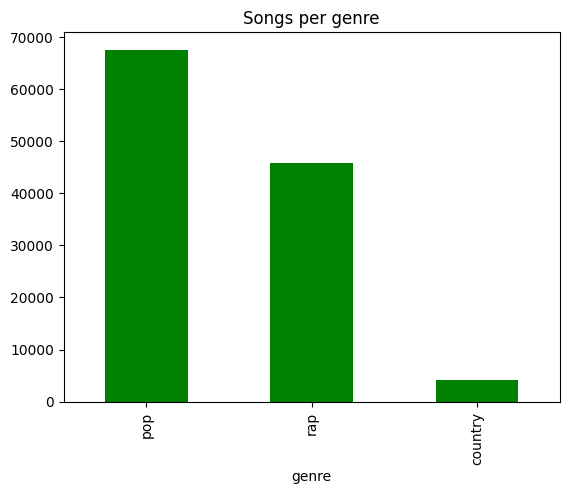

In [12]:
# bar chart: songs per genre
df["genre"].value_counts().plot(kind="bar", color="green", title="Songs per genre")
plt.show()

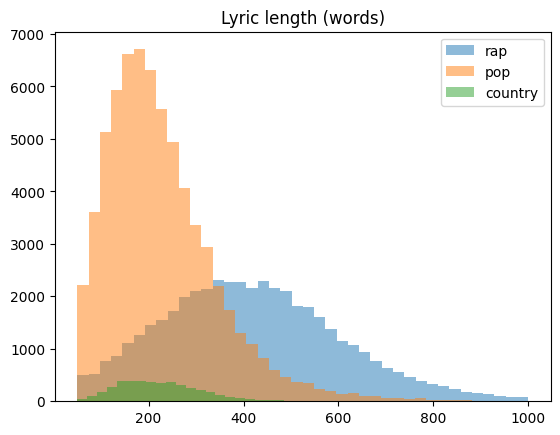

In [13]:
# overlapping histograms: lyric length by genre
for genre in GENRES:
    songs = df[df["genre"] == genre]
    plt.hist(songs["n_words"], bins=40, alpha=0.5, label=genre)
plt.title("Lyric length (words)")
plt.legend()
plt.show()

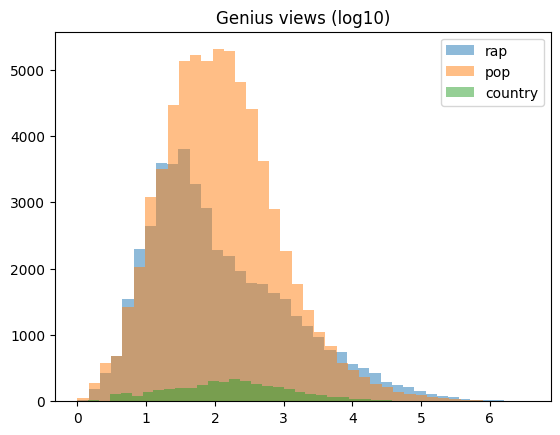

In [14]:
# overlapping histograms: views by genre (log scale because views vary widely)
for genre in GENRES:
    songs = df[df["genre"] == genre]
    plt.hist(np.log10(songs["views"] + 1), bins=40, alpha=0.5, label=genre)
plt.title("Genius views (log10)")
plt.legend()
plt.show()

**Limitation to mention:** views are cumulative, so older songs have had more time to collect them. Popularity is not directly comparable across years or genres.

## Step 3: Label each song's theme
The dataset has no theme labels, so keyword lists give a first attempt. Read sample songs and edit the lists if the labels look wrong.

In [15]:
# words suggesting a love and relationships theme
love_words = ["love", "loved", "loving", "lover", "kiss", "heart", "baby", "darling",
              "honey", "girlfriend", "boyfriend", "romance", "miss", "together",
              "forever", "hold", "touch", "tonight", "lips", "marry"]

# words suggesting a personal struggle or identity theme
struggle_words = ["struggle", "pain", "hurt", "fight", "alone", "lonely", "broken",
                  "scars", "survive", "hustle", "demons", "tears", "cry", "lost",
                  "doubt", "fear", "afraid", "myself", "identity", "proud", "grind"]

In [16]:
def keyword_score(text, keyword_list):
    # percent of the song's words found in the keyword list
    words = get_words(text)
    if len(words) == 0:
        return 0
    matches = 0
    for word in words:
        if word in keyword_list:
            matches = matches + 1
    return matches / len(words) * 100

df["love_score"] = df["lyrics"].apply(lambda text: keyword_score(text, love_words))
df["struggle_score"] = df["lyrics"].apply(lambda text: keyword_score(text, struggle_words))
df[["title", "love_score", "struggle_score"]].head()

,title,love_score,struggle_score
0,Talkin Loud Ain’t Saying Nothin,0.232558,0.000000
1,Guilty Pleasure,0.738916,0.000000
2,Soldiers of Fortune,0.360360,0.180180
3,L. Money Freestyle,0.446429,0.000000
4,Hold Ground,1.981707,0.609756


In [17]:
def pick_theme(love, struggle):
    # a theme is assigned only when one score is clearly larger than the other
    if love >= 1.5 and love >= 1.5 * struggle:
        return "love"
    elif struggle >= 1.5 and struggle >= 1.5 * love:
        return "struggle"
    else:
        return "other"

df["theme"] = [pick_theme(l, s) for l, s in zip(df["love_score"], df["struggle_score"])]

# song counts per genre and theme
pd.crosstab(df["genre"], df["theme"])

theme,love,other,struggle
genre,,,
country,1460,2433,326
pop,21052,39663,6898
rap,5405,38334,2016


In [18]:
# print 3 random songs per genre and theme to check the labels by eye
for genre in GENRES:
    for theme in ["love", "struggle"]:
        group = df[(df["genre"] == genre) & (df["theme"] == theme)]
        examples = group.sample(min(3, len(group)), random_state=1)
        for index, song in examples.iterrows():
            first_lines = " / ".join(song["lyrics"].split("\n")[:3])
            print(genre, "|", theme, "|", song["title"], "-", song["artist"])
            print("    ", first_lines)

rap | love | Cottonmouth Queen - Duch Dillinger
     VERSE 1 /  / Its Duch D-I-L-L-I-N-G-E-Rrrrrrrr
rap | love | Hear Me Out - Lil Kee
     If I gave you everything, would you take pain away / Look me right up in my face, tell me its gone be ok / Just dont let me starve again, you can come ride the wave
rap | love | Identity - Ondre
     Mind, heart, soul, body / Mind heart soul body / Mind, heart, soul body
rap | struggle | Best song we ever made - Crazy Jamez
     Im sick of this pain,all i wanna do is escape seeing in my dreams r innocent people locked in chains getting blown / Up by granades people always crushing plains look at my age this stage this day im so afraid dont know what to say young / Kids getting brain washed seeing bloodstains on walls plus snorting cokeane thats a shame look deep in my eyes see the
rap | struggle | LETTING GO - TshiDaMagg
     (Intro) / Mr Mc / Huhhh
rap | struggle | Blind man - Akon
     Tell me why the blind man cries / Oh, he sheds a tear because

Count how many sample songs fit their label per genre and theme; this gives a quick quality estimate to report.

## Step 4: Balanced sample for annotation
Equal numbers of songs per genre and theme keep subject matter from driving differences in wordplay and metaphor.

In [19]:
# songs per genre-theme cell: 3 genres x 2 themes x 40 = 240 songs
SONGS_PER_CELL = 40

sample_pieces = []

for genre in GENRES:
    for theme in ["love", "struggle"]:
        group = df[(df["genre"] == genre) & (df["theme"] == theme)]
        group = group.sample(frac=1, random_state=42)       # shuffle the rows
        group = group.drop_duplicates(subset="artist")      # at most one song per artist
        group = group.head(SONGS_PER_CELL)                  # keep the first 40
        sample_pieces.append(group)

annotation_set = pd.concat(sample_pieces, ignore_index=True)

print(pd.crosstab(annotation_set["genre"], annotation_set["theme"]))
print("Total songs:", len(annotation_set))
print("Total words:", annotation_set["n_words"].sum())

theme    love  struggle
genre                  
country    40        40
pop        40        40
rap        40        40
Total songs: 240
Total words: 64249


In [20]:
# save song info without lyrics (safe to share in the public repo)
safe_columns = ["id", "title", "artist", "genre", "theme", "year", "views", "n_words"]
annotation_set[safe_columns].to_csv("annotation_songs.csv", index=False)

A cell with fewer than 40 songs shows a smaller count. Lower `SONGS_PER_CELL` or raise `KEEP_FRACTION` to fill it.

## Step 5: Simple features for Experiment 2
- **Lexical diversity:** unique words divided by total words
- **Repetition:** share of lines that repeat an earlier line
- **Sentiment:** tone from -1 (negative) to +1 (positive)

In [21]:
# pip install vaderSentiment (once, in the terminal)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sentiment_tool = SentimentIntensityAnalyzer()

def lexical_diversity(text):
    words = get_words(text)
    if len(words) == 0:
        return 0
    # set() keeps only the unique words
    return len(set(words)) / len(words)

def repetition(text):
    # non-empty lines, lowercased
    lines = [line.strip().lower() for line in text.split("\n") if line.strip() != ""]
    if len(lines) == 0:
        return 0
    # 0 means no repeated lines
    return 1 - len(set(lines)) / len(lines)

def sentiment(text):
    # compound score summarizes overall tone
    return sentiment_tool.polarity_scores(text)["compound"]

In [22]:
# features on 2,000 random songs (the full set takes longer)
demo = df.sample(min(2000, len(df)), random_state=1).copy()

demo["lexical_diversity"] = demo["lyrics"].apply(lexical_diversity)
demo["repetition"] = demo["lyrics"].apply(repetition)
demo["sentiment"] = demo["lyrics"].apply(sentiment)

# average of each feature per genre
demo.groupby("genre")[["lexical_diversity", "repetition", "sentiment"]].mean().round(3)

,lexical_diversity,repetition,sentiment
genre,,,
country,0.439,0.257,0.419
pop,0.438,0.271,0.337
rap,0.453,0.179,-0.149


## Still to do (next updates)
- Annotate wordplay and metaphor in the sampled songs, with a second annotator on a shared subset
- Calculate instances per 1,000 words and compare genres and themes
- Predict popularity (log of views) from genre and year, then test whether the linguistic features improve predictions on held-out artists